In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
import random
import seaborn as sns
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.metrics import confusion_matrix
from PIL import Image
from collections import Counter
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models


In [2]:
path = kagglehub.dataset_download(
    "mahmoudreda55/satellite-image-classification"
)

print("Caminho do dataset:", path)
print("\nConteúdo encontrado:")
print(os.listdir(path))

Using Colab cache for faster access to the 'satellite-image-classification' dataset.
Caminho do dataset: /kaggle/input/satellite-image-classification

Conteúdo encontrado:
['data']


In [3]:
data_dir = os.path.join(path, "data")

print("Caminho das imagens:", data_dir)
print("\nPastas encontradas:")

for item in sorted(os.listdir(data_dir)):
    caminho = os.path.join(data_dir, item)

    if os.path.isdir(caminho):
        print(f"{item}: pasta")

Caminho das imagens: /kaggle/input/satellite-image-classification/data

Pastas encontradas:
cloudy: pasta
desert: pasta
green_area: pasta
water: pasta


In [4]:

extensoes_validas = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for classe in sorted(os.listdir(data_dir)):
    pasta = os.path.join(data_dir, classe)

    if os.path.isdir(pasta):
        arquivos = os.listdir(pasta)

        imagens = [
            f for f in arquivos
            if f.lower().endswith(extensoes_validas)
            and os.path.isfile(os.path.join(pasta, f))
        ]

        outros = len(arquivos) - len(imagens)

        print(f"Classe: {classe}")
        print(f"  Total de imagens: {len(imagens)}")
        print(f"  Outros arquivos: {outros}")

Classe: cloudy
  Total de imagens: 1500
  Outros arquivos: 0
Classe: desert
  Total de imagens: 1131
  Outros arquivos: 0
Classe: green_area
  Total de imagens: 1500
  Outros arquivos: 0
Classe: water
  Total de imagens: 1500
  Outros arquivos: 0


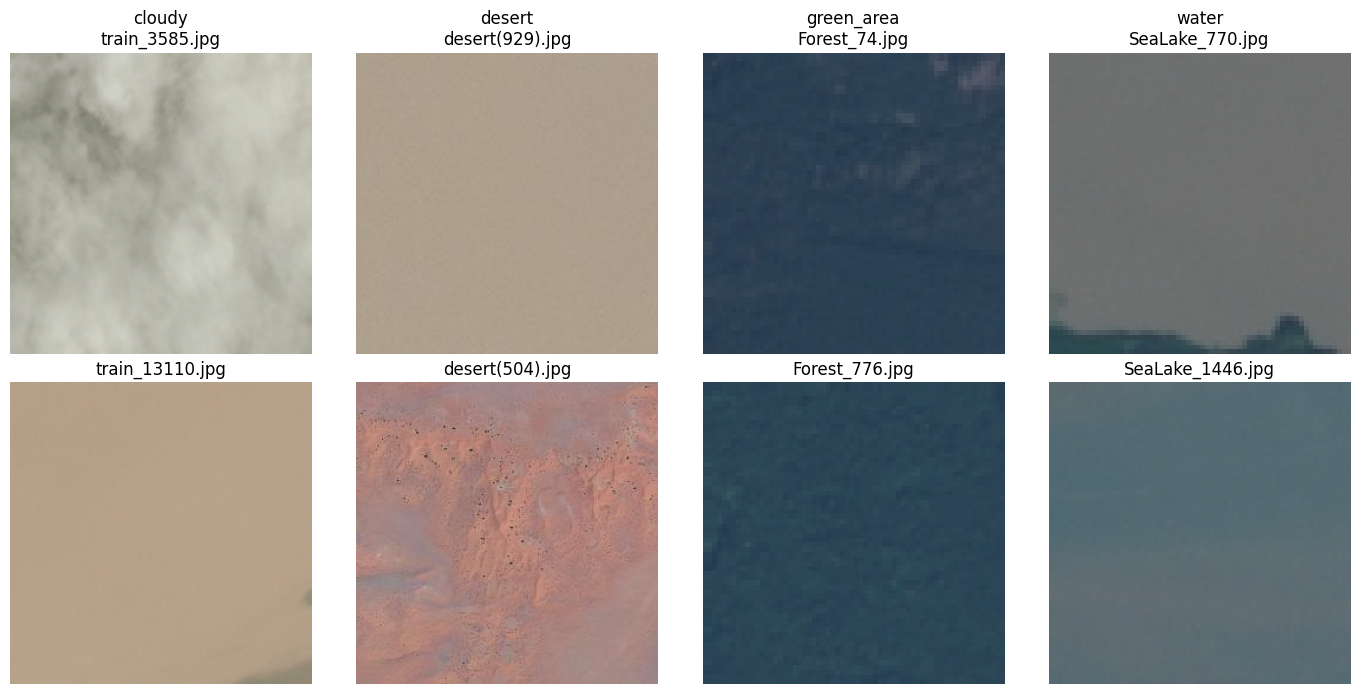

In [5]:
classes = sorted([
    nome for nome in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, nome))
])

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for coluna, classe in enumerate(classes):
    pasta = os.path.join(data_dir, classe)
    arquivos = [
        f for f in os.listdir(pasta)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    amostras = random.sample(arquivos, 2)

    for linha, arquivo in enumerate(amostras):
        caminho = os.path.join(pasta, arquivo)

        with Image.open(caminho) as imagem:
            imagem = imagem.convert("RGB")
            axes[linha, coluna].imshow(imagem)

        axes[linha, coluna].set_title(
            f"{classe}\n{arquivo}" if linha == 0 else arquivo
        )
        axes[linha, coluna].axis("off")

plt.tight_layout()
plt.show()

In [6]:
extensoes = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for classe in sorted(os.listdir(data_dir)):
    pasta = os.path.join(data_dir, classe)

    if not os.path.isdir(pasta):
        continue

    arquivos = [
        f for f in os.listdir(pasta)
        if f.lower().endswith(extensoes)
    ]

    amostra = random.sample(arquivos, min(50, len(arquivos)))
    dimensoes = Counter()
    modos = Counter()

    for arquivo in amostra:
        caminho = os.path.join(pasta, arquivo)

        with Image.open(caminho) as img:
            dimensoes[img.size] += 1
            modos[img.mode] += 1

    print(f"\nClasse: {classe}")
    print("Dimensões encontradas (amostra):", dimensoes.most_common(5))
    print("Modos de cor:", modos)


Classe: cloudy
Dimensões encontradas (amostra): [((256, 256), 50)]
Modos de cor: Counter({'CMYK': 50})

Classe: desert
Dimensões encontradas (amostra): [((256, 256), 50)]
Modos de cor: Counter({'RGB': 50})

Classe: green_area
Dimensões encontradas (amostra): [((64, 64), 50)]
Modos de cor: Counter({'RGB': 50})

Classe: water
Dimensões encontradas (amostra): [((64, 64), 50)]
Modos de cor: Counter({'RGB': 50})


In [7]:
SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True
)

temp_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

total_batches = tf.data.experimental.cardinality(temp_ds).numpy()
val_batches = total_batches // 2

val_ds = temp_ds.take(val_batches)
test_ds = temp_ds.skip(val_batches)

print("\nClasses:", class_names)
print("Lotes de treinamento:", tf.data.experimental.cardinality(train_ds).numpy())
print("Lotes de validação:", tf.data.experimental.cardinality(val_ds).numpy())
print("Lotes de teste:", tf.data.experimental.cardinality(test_ds).numpy())

Found 5631 files belonging to 4 classes.
Using 3942 files for training.
Found 5631 files belonging to 4 classes.
Using 1689 files for validation.

Classes: ['cloudy', 'desert', 'green_area', 'water']
Lotes de treinamento: 124
Lotes de validação: 26
Lotes de teste: 27


In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def preparar_imagens(imagens, rotulos):
    imagens = preprocess_input(imagens)
    return imagens, rotulos

train_ds = train_ds.map(
    preparar_imagens,
    num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.map(
    preparar_imagens,
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.map(
    preparar_imagens,
    num_parallel_calls=AUTOTUNE
)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [9]:
for imagens, rotulos in train_ds.take(1):
    print("Formato do lote:", imagens.shape)
    print("Formato dos rótulos:", rotulos.shape)
    print("Valor mínimo após preprocess_input:", tf.reduce_min(imagens).numpy())
    print("Valor máximo após preprocess_input:", tf.reduce_max(imagens).numpy())
    print("Rótulos do lote:", rotulos[:10].numpy())
    print("Nomes das classes:", class_names)

Formato do lote: (32, 128, 128, 3)
Formato dos rótulos: (32,)
Valor mínimo após preprocess_input: -123.68
Valor máximo após preprocess_input: 134.311
Rótulos do lote: [1 0 3 2 0 3 0 0 2 2]
Nomes das classes: ['cloudy', 'desert', 'green_area', 'water']


In [10]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(4, activation="softmax")
])

model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,500 (90.98 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [11]:

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)


In [12]:
file_paths = []
labels = []

for label, class_name in enumerate(class_names):
    folder = os.path.join(data_dir, class_name)

    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            file_paths.append(os.path.join(folder, filename))
            labels.append(label)

train_paths, test_paths, train_labels, test_labels = train_test_split(
    file_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)


def load_image(path, label):
    def read_image(p):
        p = p.numpy().decode("utf-8")
        with Image.open(p) as img:
            return np.asarray(
                img.convert("RGB").resize((128, 128)),
                dtype=np.float32
            )

    image = tf.py_function(read_image, [path], Tout=tf.float32)
    image.set_shape([128, 128, 3])
    image = preprocess_input(image)

    return image, label


def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, training=True)
test_ds = make_dataset(test_paths, test_labels)

In [13]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [14]:

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    min_delta=0.0001,
    restore_best_weights=True,
    verbose=1
)

# Treinamento do modelo
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    callbacks=[early_stop]
)


Epoch 1/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 47s 232ms/step - accuracy: 0.9483 - loss: 0.1540 - val_accuracy: 0.9940 - val_loss: 0.0270
Epoch 2/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 17s 121ms/step - accuracy: 0.9911 - loss: 0.0344 - val_accuracy: 0.9952 - val_loss: 0.0202
Epoch 3/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 17s 123ms/step - accuracy: 0.9953 - loss: 0.0178 - val_accuracy: 0.9976 - val_loss: 0.0100
Epoch 4/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 17s 119ms/step - accuracy: 0.9971 - loss: 0.0130 - val_accuracy: 0.9964 - val_loss: 0.0116
Epoch 5/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 17s 120ms/step - accuracy: 0.9976 - loss: 0.0098 - val_accuracy: 0.9976 - val_loss: 0.0115
Epoch 6/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 17s 120ms/step - accuracy: 0.9987 - loss: 0.0065 - val_accuracy: 0.9976 - val_loss: 0.0062
Epoch 7/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 17s 119ms/step - accuracy: 0.9987 - loss: 0.0041 - val_accuracy: 0.9976 - val_loss: 0.0092
Epoch 8/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 18s 126ms/step - accuracy: 0.9978 -

In [15]:

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"\nPerda no teste: {test_loss:.4f}")
print(f"Acurácia no teste: {test_accuracy * 100:.2f}%")


36/36 ━━━━━━━━━━━━━━━━━━━━ 8s 226ms/step - accuracy: 0.9920 - loss: 0.0321

Perda no teste: 0.0321
Acurácia no teste: 99.20%


In [16]:
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))


36/36 ━━━━━━━━━━━━━━━━━━━━ 11s 213ms/step
              precision    recall  f1-score   support

      cloudy     0.9933    0.9900    0.9917       300
      desert     1.0000    1.0000    1.0000       227
  green_area     0.9966    0.9900    0.9933       300
       water     0.9802    0.9900    0.9851       300

    accuracy                         0.9920      1127
   macro avg     0.9925    0.9925    0.9925      1127
weighted avg     0.9921    0.9920    0.9920      1127



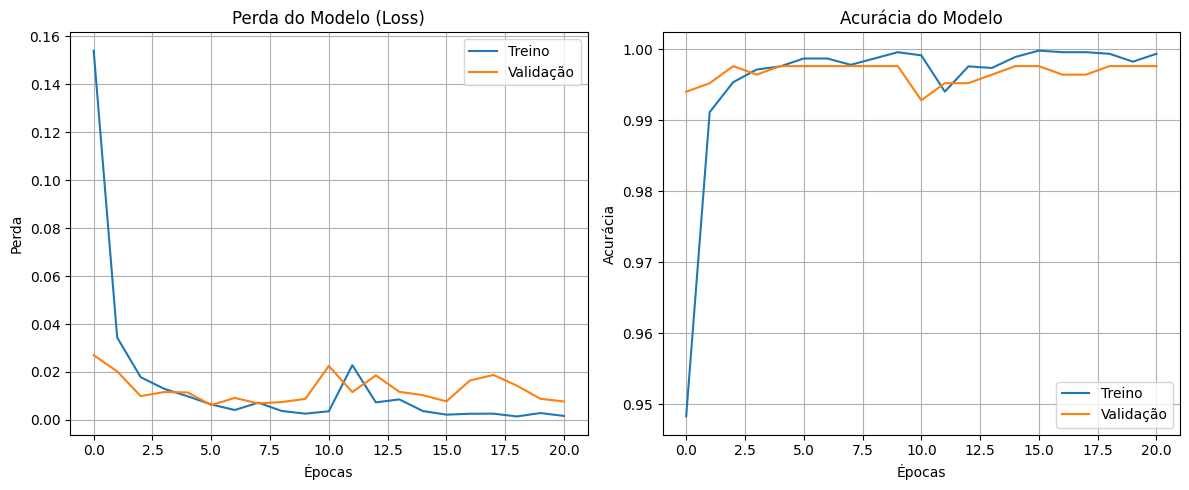

In [17]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Treino')
plt.plot(history.history['val_loss'], label='Validação')
plt.title('Perda do Modelo (Loss)')
plt.xlabel('Épocas')
plt.ylabel('Perda')
plt.legend()
plt.grid(True)


plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Treino')
plt.plot(history.history['val_accuracy'], label='Validação')
plt.title('Acurácia do Modelo')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

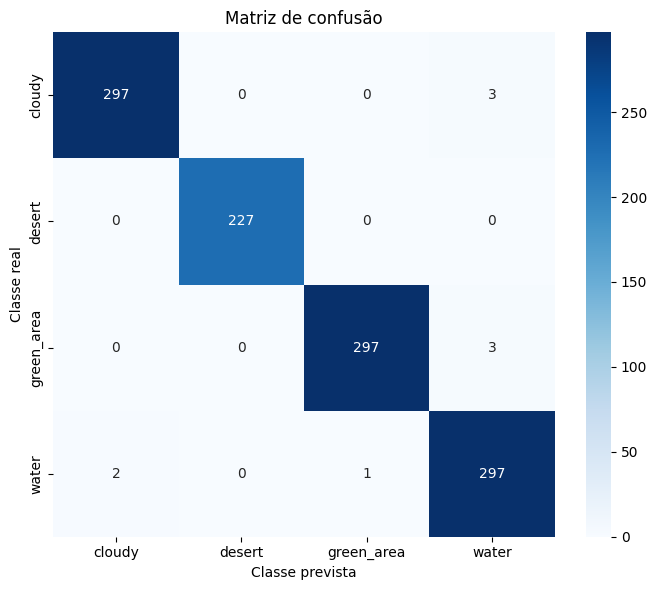

In [18]:
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Matriz de confusão")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()

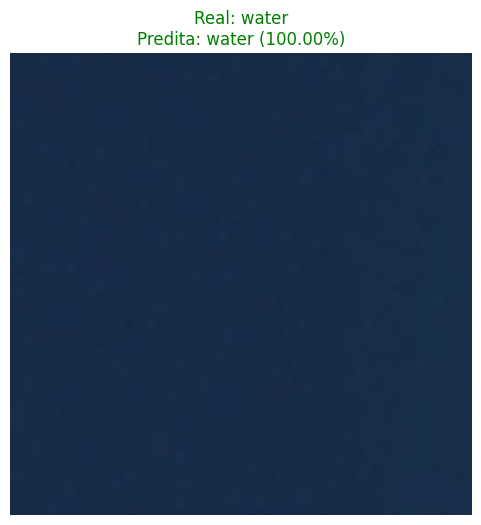

Arquivo: SeaLake_1564.jpg
Classe real: water
Classe prevista: water
Confiança: 100.00%
Resultado: ACERTOU

Probabilidades por classe:
cloudy: 0.00%
desert: 0.00%
green_area: 0.00%
water: 100.00%


In [19]:
class_names = ['cloudy', 'desert', 'green_area', 'water']


classe = "water"

pasta = os.path.join(data_dir, classe)


arquivos = [
    nome for nome in os.listdir(pasta)
    if nome.lower().endswith((".jpg", ".jpeg", ".png"))
]

if not arquivos:
    raise ValueError(f"Nenhuma imagem encontrada na pasta: {pasta}")

nome_imagem = random.choice(arquivos)
caminho_imagem = os.path.join(pasta, nome_imagem)


img = load_img(
    caminho_imagem,
    target_size=(128, 128),
    color_mode="rgb"
)
img_array = img_to_array(img)

entrada = np.expand_dims(img_array, axis=0)
entrada = preprocess_input(entrada)


predicao = model.predict(entrada, verbose=0)[0]

indice_predito = np.argmax(predicao)
classe_predita = class_names[indice_predito]
confianca = predicao[indice_predito] * 100

plt.figure(figsize=(6, 6))
plt.imshow(load_img(caminho_imagem))
plt.axis("off")
plt.title(
    f"Real: {classe}\n"
    f"Predita: {classe_predita} ({confianca:.2f}%)",
    color="green" if classe == classe_predita else "red"
)
plt.show()


print("Arquivo:", nome_imagem)
print("Classe real:", classe)
print("Classe prevista:", classe_predita)
print(f"Confiança: {confianca:.2f}%")
print("Resultado:", "ACERTOU" if classe == classe_predita else "ERROU")

print("\nProbabilidades por classe:")
for nome, probabilidade in zip(class_names, predicao):
    print(f"{nome}: {probabilidade * 100:.2f}%")


In [20]:

model.save("modelo_satellite.keras")

In [21]:
!pip install shap

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_175
Received: inputs=['Tensor(shape=(5, 128, 128, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_175
Received: inputs=['Tensor(shape=(50, 128, 128, 3))']
  warnings.warn(msg)


Classe prevista: water, Classe real: water


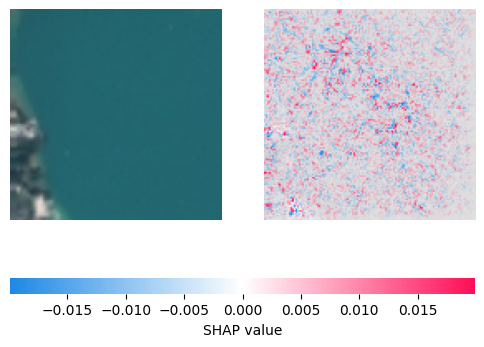

Classe prevista: green_area, Classe real: green_area


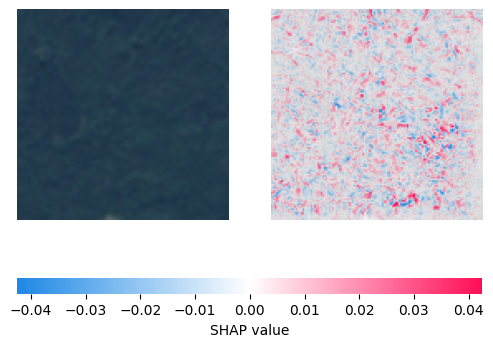

Classe prevista: cloudy, Classe real: cloudy


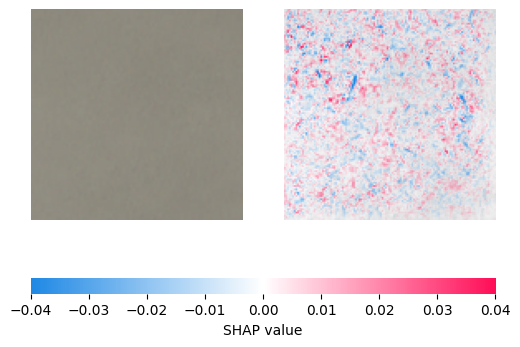

Classe prevista: water, Classe real: water


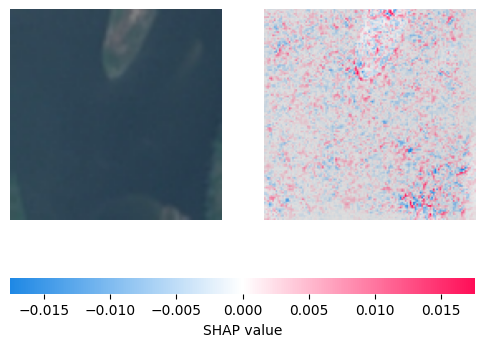

Classe prevista: green_area, Classe real: green_area


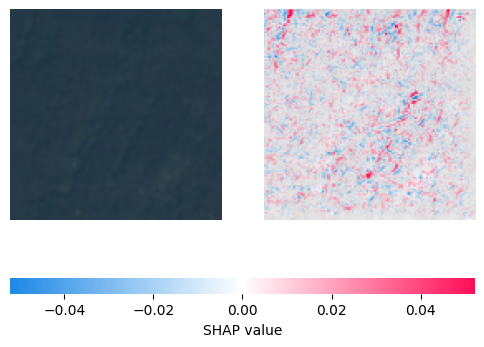

In [22]:
import shap
background = np.concatenate(
    [x.numpy() for x, y in train_ds.take(4)],
    axis=0
)[:100]

test_images = []
test_labels = []

for images, labels in test_ds.take(1):
    test_images = images.numpy()[:5]
    test_labels = labels.numpy()[:5]

test_sample = test_images

preds = model.predict(test_sample, verbose=0)
pred_classes = np.argmax(preds, axis=1)
real_classes = test_labels.astype(int)


explainer = shap.GradientExplainer(model, background)
shap_values = explainer.shap_values(test_sample)


for i in range(len(test_sample)):
    print(
        f"Classe prevista: {class_names[pred_classes[i]]}, "
        f"Classe real: {class_names[real_classes[i]]}"
    )

    if isinstance(shap_values, list):
        valores_imagem = shap_values[pred_classes[i]][i:i+1]
    else:
        valores = np.asarray(shap_values)

        if valores.ndim == 5:
            valores_imagem = valores[i:i+1, ..., pred_classes[i]]
        elif valores.ndim == 4:
            valores_imagem = valores[i:i+1]
        else:
            raise ValueError(
                f"Formato SHAP inesperado: {valores.shape}"
            )


    imagem_exibicao = test_sample[i:i+1].copy()
    imagem_exibicao += np.array([103.939, 116.779, 123.68])
    imagem_exibicao = imagem_exibicao[..., ::-1]
    imagem_exibicao = np.clip(imagem_exibicao, 0, 255).astype(np.uint8)

    shap.image_plot(
        [valores_imagem],
        imagem_exibicao
    )